In [1]:
# biblioteca
import tensorflow as tf
import os
import random
import numpy as np

print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  1


In [2]:
SEED = 123456  # semente fixa para reprodutibilidade
os.environ['PYTHONHASHSEED']=str(SEED)  # fixa o hash do Python
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
random.seed(SEED)  # semente do random
np.random.seed(SEED)  # semente
tf.random.set_seed(SEED)  # semente

In [3]:
from tensorflow.keras.datasets import fashion_mnist

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()  # carrega 60k imagens de treino e 10k de teste
assert x_train.shape == (60000, 28, 28)  # confere as dimensões
assert x_test.shape == (10000, 28, 28)
assert y_train.shape == (60000,)
assert y_test.shape == (10000,)

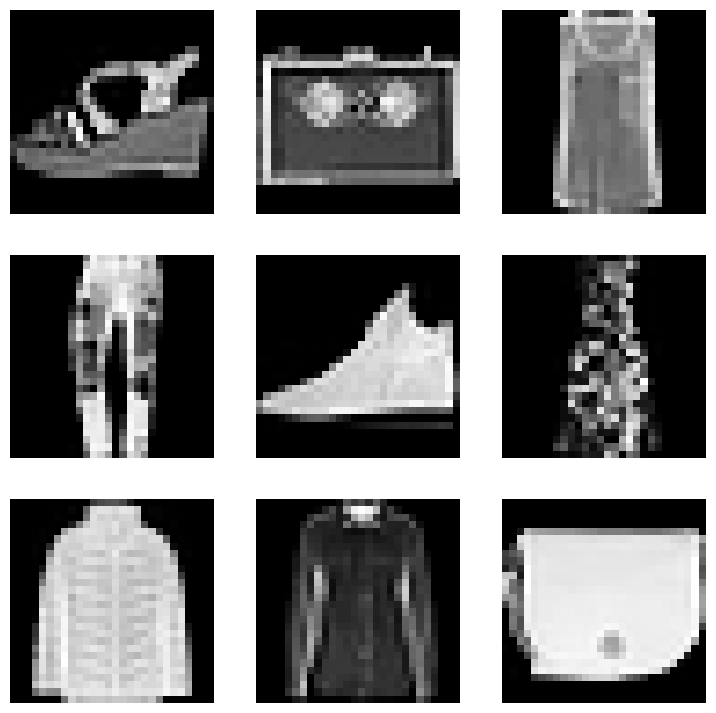

In [4]:
import numpy as np
from matplotlib import pyplot as plt

plt.figure(figsize=(9, 9))  # figura 9x9

# Choose 9 samples out of 60K available in the train set
rndSamples = np.random.choice(60000, 9)  # sorteia 9 índices

for i in range(9):
    plt.subplot(3,3,i+1)  # grade 3x3
    plt.imshow(x_train[rndSamples[i]], cmap="Greys_r")  # mostra em tons de cinza
    plt.axis('off')

plt.show();

In [5]:
dataset = np.concatenate([x_train, x_test], axis=0)  # junta treino e teste
dataset = np.expand_dims(dataset, -1).astype("float32") / 255  # adiciona canal

In [6]:
from tensorflow import keras
from tensorflow.keras import layers

# Create a sampling layer
class SamplingLayer(layers.Layer):  # camada do reparameterization trick
  """Reparameterization Trick z = mu + sigma * epsilon"""

  def call(self, inputs):
    zMean, zLogVar = inputs  # média e log da variância
    batch = tf.shape(zMean)[0]  # tamanho do lote
    dim = tf.shape(zMean)[1]  # dimensão do latente
    epsilon = tf.keras.backend.random_normal(shape=(batch, dim))  # ruído
    return zMean + tf.exp(0.5 * zLogVar) * epsilon

In [7]:
def buildEncoder(latentDim, encoderInputs): # modelo dequencial para o aprendizado das caracteristicas da imagem
  l1 = keras.models.Sequential([
    layers.Conv2D(128, 3, activation="relu", strides=2, padding="same"),
    layers.Conv2D(64, 3, activation="relu", strides=2, padding="same"),
    layers.Flatten(),  # achata para vetor
    layers.Dense(256, activation="relu")  # camada densa intermediária
  ])

  x = l1(encoderInputs)

  zMean = layers.Dense(latentDim, name="z_mean")(x)  # saída da média

  zLogVar = layers.Dense(latentDim, name="z_log_var")(x)  # saída do log-variância

  z = SamplingLayer()([zMean, zLogVar])  # amostra z

  return keras.Model(encoderInputs, [zMean, zLogVar, z], name="encoder")  # encoder devolve mu, logvar e z

encoderInputs = keras.Input(shape=(28, 28, 1))  # entrada 28x28x1
encoder = buildEncoder(2, encoderInputs)  # latente de dimensão 2
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 256)       │    878,144 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        514 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        514 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_layer      │ (None, 2)         │          0 │ z_mean[0][0],     │
│ (SamplingLayer)     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 879,172 (3.35 MB)

 Trainable params: 879,172 (3.35 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
def buildDecoder(latentInputs):

  l1 = keras.models.Sequential([
    layers.Dense(7*7*64, activation="relu", input_shape=(latentInputs.shape[1],)),
    layers.Reshape((7,7,64)),  # volta ao formato de imagem
    layers.Conv2DTranspose(128, 3, activation="relu", strides=2, padding="same"),
    layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same"),
    layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")
  ])

  return keras.Model(latentInputs, l1(latentInputs), name="decoder")

# construção do atual modelo
latentInputs = keras.Input(shape=(2,))  # entrada: ponto z 2D
decoder = buildDecoder(latentInputs)
decoder.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 28, 28, 1)      │       157,633 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,633 (615.75 KB)

 Trainable params: 157,633 (615.75 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
def reconstructionLoss(data, reconstructed):
  return tf.reduce_mean(
      tf.reduce_sum(
          keras.losses.binary_crossentropy(data, reconstructed),  # BCE por pixel
          axis=(1, 2)  # soma sobre a imagem, média no lote
      )
  )

In [10]:
def klDivergenceLoss(zMean, zLogVar):
  return tf.reduce_mean(
      tf.reduce_sum(
          -0.5 * (1 + zLogVar - tf.square(zMean) - tf.exp(zLogVar)),  # KL fechada entre N(mu,sigma²) e N(0,1)
          axis=1  # soma sobre as dimensões do latente
      )
  )

In [11]:
def calcTotalLoss(data, reconstructed, zMean, zLogVar):
  loss1 = reconstructionLoss(data, reconstructed)  # perda de reconstrução
  loss2 = klDivergenceLoss(zMean, zLogVar)  # perda KL
  klWeight = 3.0  # peso >1 = Beta-VAE (latente mais organizado, imagem mais borrada)
  return  loss1, loss2, loss1 + klWeight * loss2  # total = rec + 3*KL

In [12]:
class VAE(keras.Model):  # modelo que junta encoder e decoder
  def __init__(self, encoder, decoder, **kwargs):
    super(VAE, self).__init__(**kwargs)
    self.encoder = encoder
    self.decoder = decoder
    # registra as perdas como métricas no histórico de treino
    self.totalLossTracker = keras.metrics.Mean(name="total_loss")  # média da perda total
    self.ceLossTracker = keras.metrics.Mean(name="ce_loss")  # média da reconstrução
    self.klLossTracker = keras.metrics.Mean(name="kl_loss")  # média da KL

  # métricas observáveis
  @property
  def metrics(self):  # métricas zeradas a cada época
    return [
        self.totalLossTracker,
        self.ceLossTracker,
        self.klLossTracker
    ]

  # calcula a perda, os gradientes e atualiza os pesos
  def train_step(self, data):  # passo de treino personalizado
    # o GradientTape registra as operações para calcular os gradientes
    # dos pesos treináveis que serão atualizados
    with tf.GradientTape() as tape:
        # passagem direta (forward)
        zMean, zLogVar, z = self.encoder(data)  # codifica
        reconstruction = self.decoder(z)  # decodifica
        ceLoss, klLoss, totalLoss = calcTotalLoss(data, reconstruction, zMean, zLogVar)  # calcula as perdas
    # retropropagação (backward)
    grads = tape.gradient(totalLoss, self.trainable_weights)  # gradientes da perda total
    self.optimizer.apply_gradients(zip(grads, self.trainable_weights))  # atualiza os pesos

    # atualiza o acompanhamento das perdas
    self.totalLossTracker.update_state(totalLoss)
    self.ceLossTracker.update_state(ceLoss)
    self.klLossTracker.update_state(klLoss)

    # devolve as perdas para o objeto history
    return {
        "total_loss": self.totalLossTracker.result(),
        "ce_loss": self.ceLossTracker.result(),
        "kl_loss": self.klLossTracker.result()
    }

In [13]:
vae = VAE(encoder, decoder)  # instancia o VAE
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001))
history = vae.fit(dataset, epochs=32, batch_size=128)  # 32 épocas, lote 128

Epoch 1/32
547/547 ━━━━━━━━━━━━━━━━━━━━ 23s 25ms/step - ce_loss: 299.6867 - kl_loss: 3.8760 - total_loss: 311.3148
Epoch 2/32
547/547 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - ce_loss: 263.7934 - kl_loss: 4.7489 - total_loss: 278.0400
Epoch 3/32
547/547 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - ce_loss: 260.8971 - kl_loss: 4.8476 - total_loss: 275.4400
Epoch 4/32
547/547 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - ce_loss: 259.1819 - kl_loss: 4.9056 - total_loss: 273.8986
Epoch 5/32
547/547 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - ce_loss: 258.1942 - kl_loss: 4.9464 - total_loss: 273.0331
Epoch 6/32
547/547 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - ce_loss: 257.3539 - kl_loss: 4.9845 - total_loss: 272.3075
Epoch 7/32
547/547 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - ce_loss: 256.5075 - kl_loss: 5.0198 - total_loss: 271.5669
Epoch 8/32
547/547 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - ce_loss: 255.7657 - kl_loss: 5.0358 - total_loss: 270.8732
Epoch 9/32
547/547 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - ce_loss: 255.2527 - kl_loss: 5.

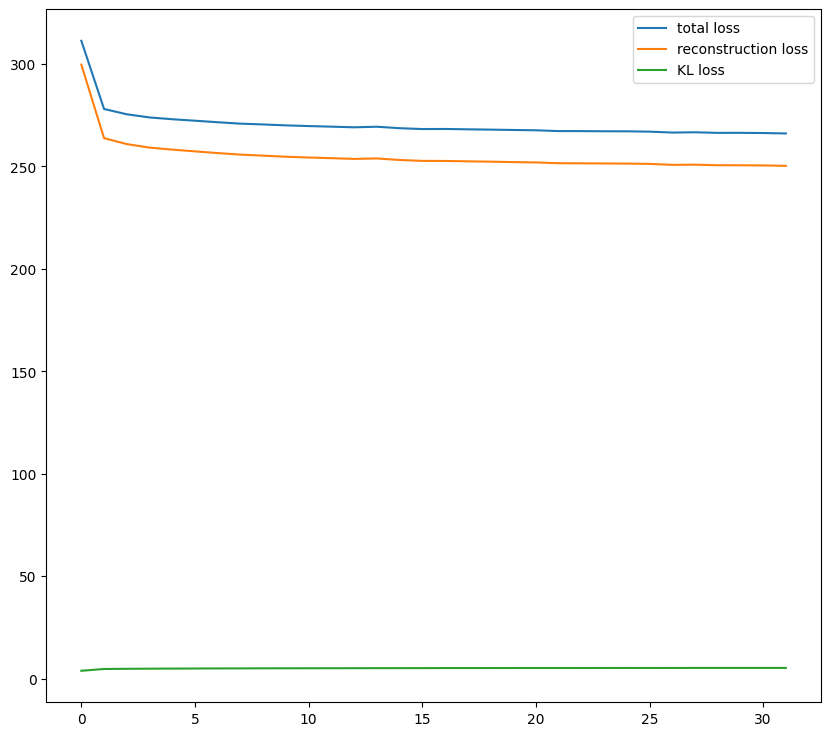

In [14]:
plt.figure(figsize=(10, 9))
plt.plot(history.history.get('total_loss'), label="total loss")
plt.plot(history.history.get('ce_loss'), label="reconstruction loss")  # domina a perda total
plt.plot(history.history.get('kl_loss'), label="KL loss")  # pequena, por isso some no gráfico
plt.legend();

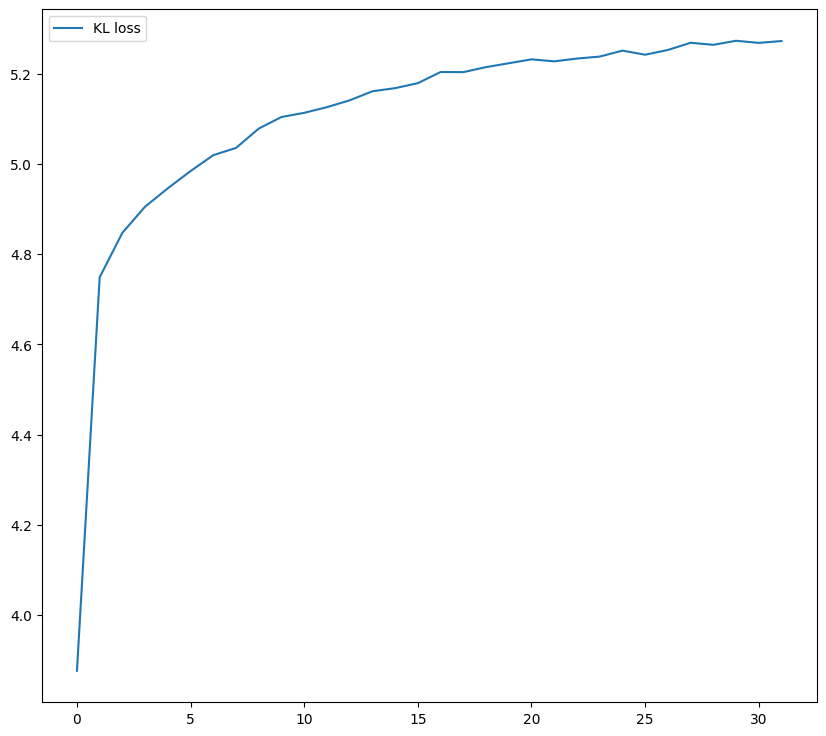

In [15]:
plt.figure(figsize=(10, 9))
plt.plot(history.history.get('kl_loss'), label="KL loss")
plt.legend();

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 569ms/step


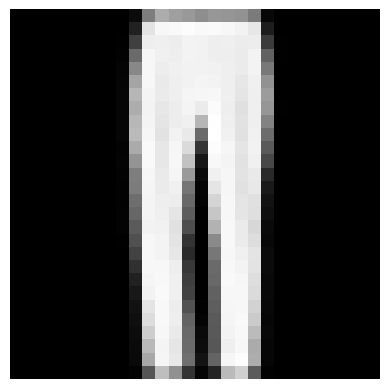

In [16]:
synth = vae.decoder.predict(np.array([[1, 2]]))  # [1, 2] é um ponto z, não mu/sigma
plt.axis('off')
plt.imshow(synth.reshape((28,28)), cmap="Greys_r");  # mostra a imagem gerada

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step  


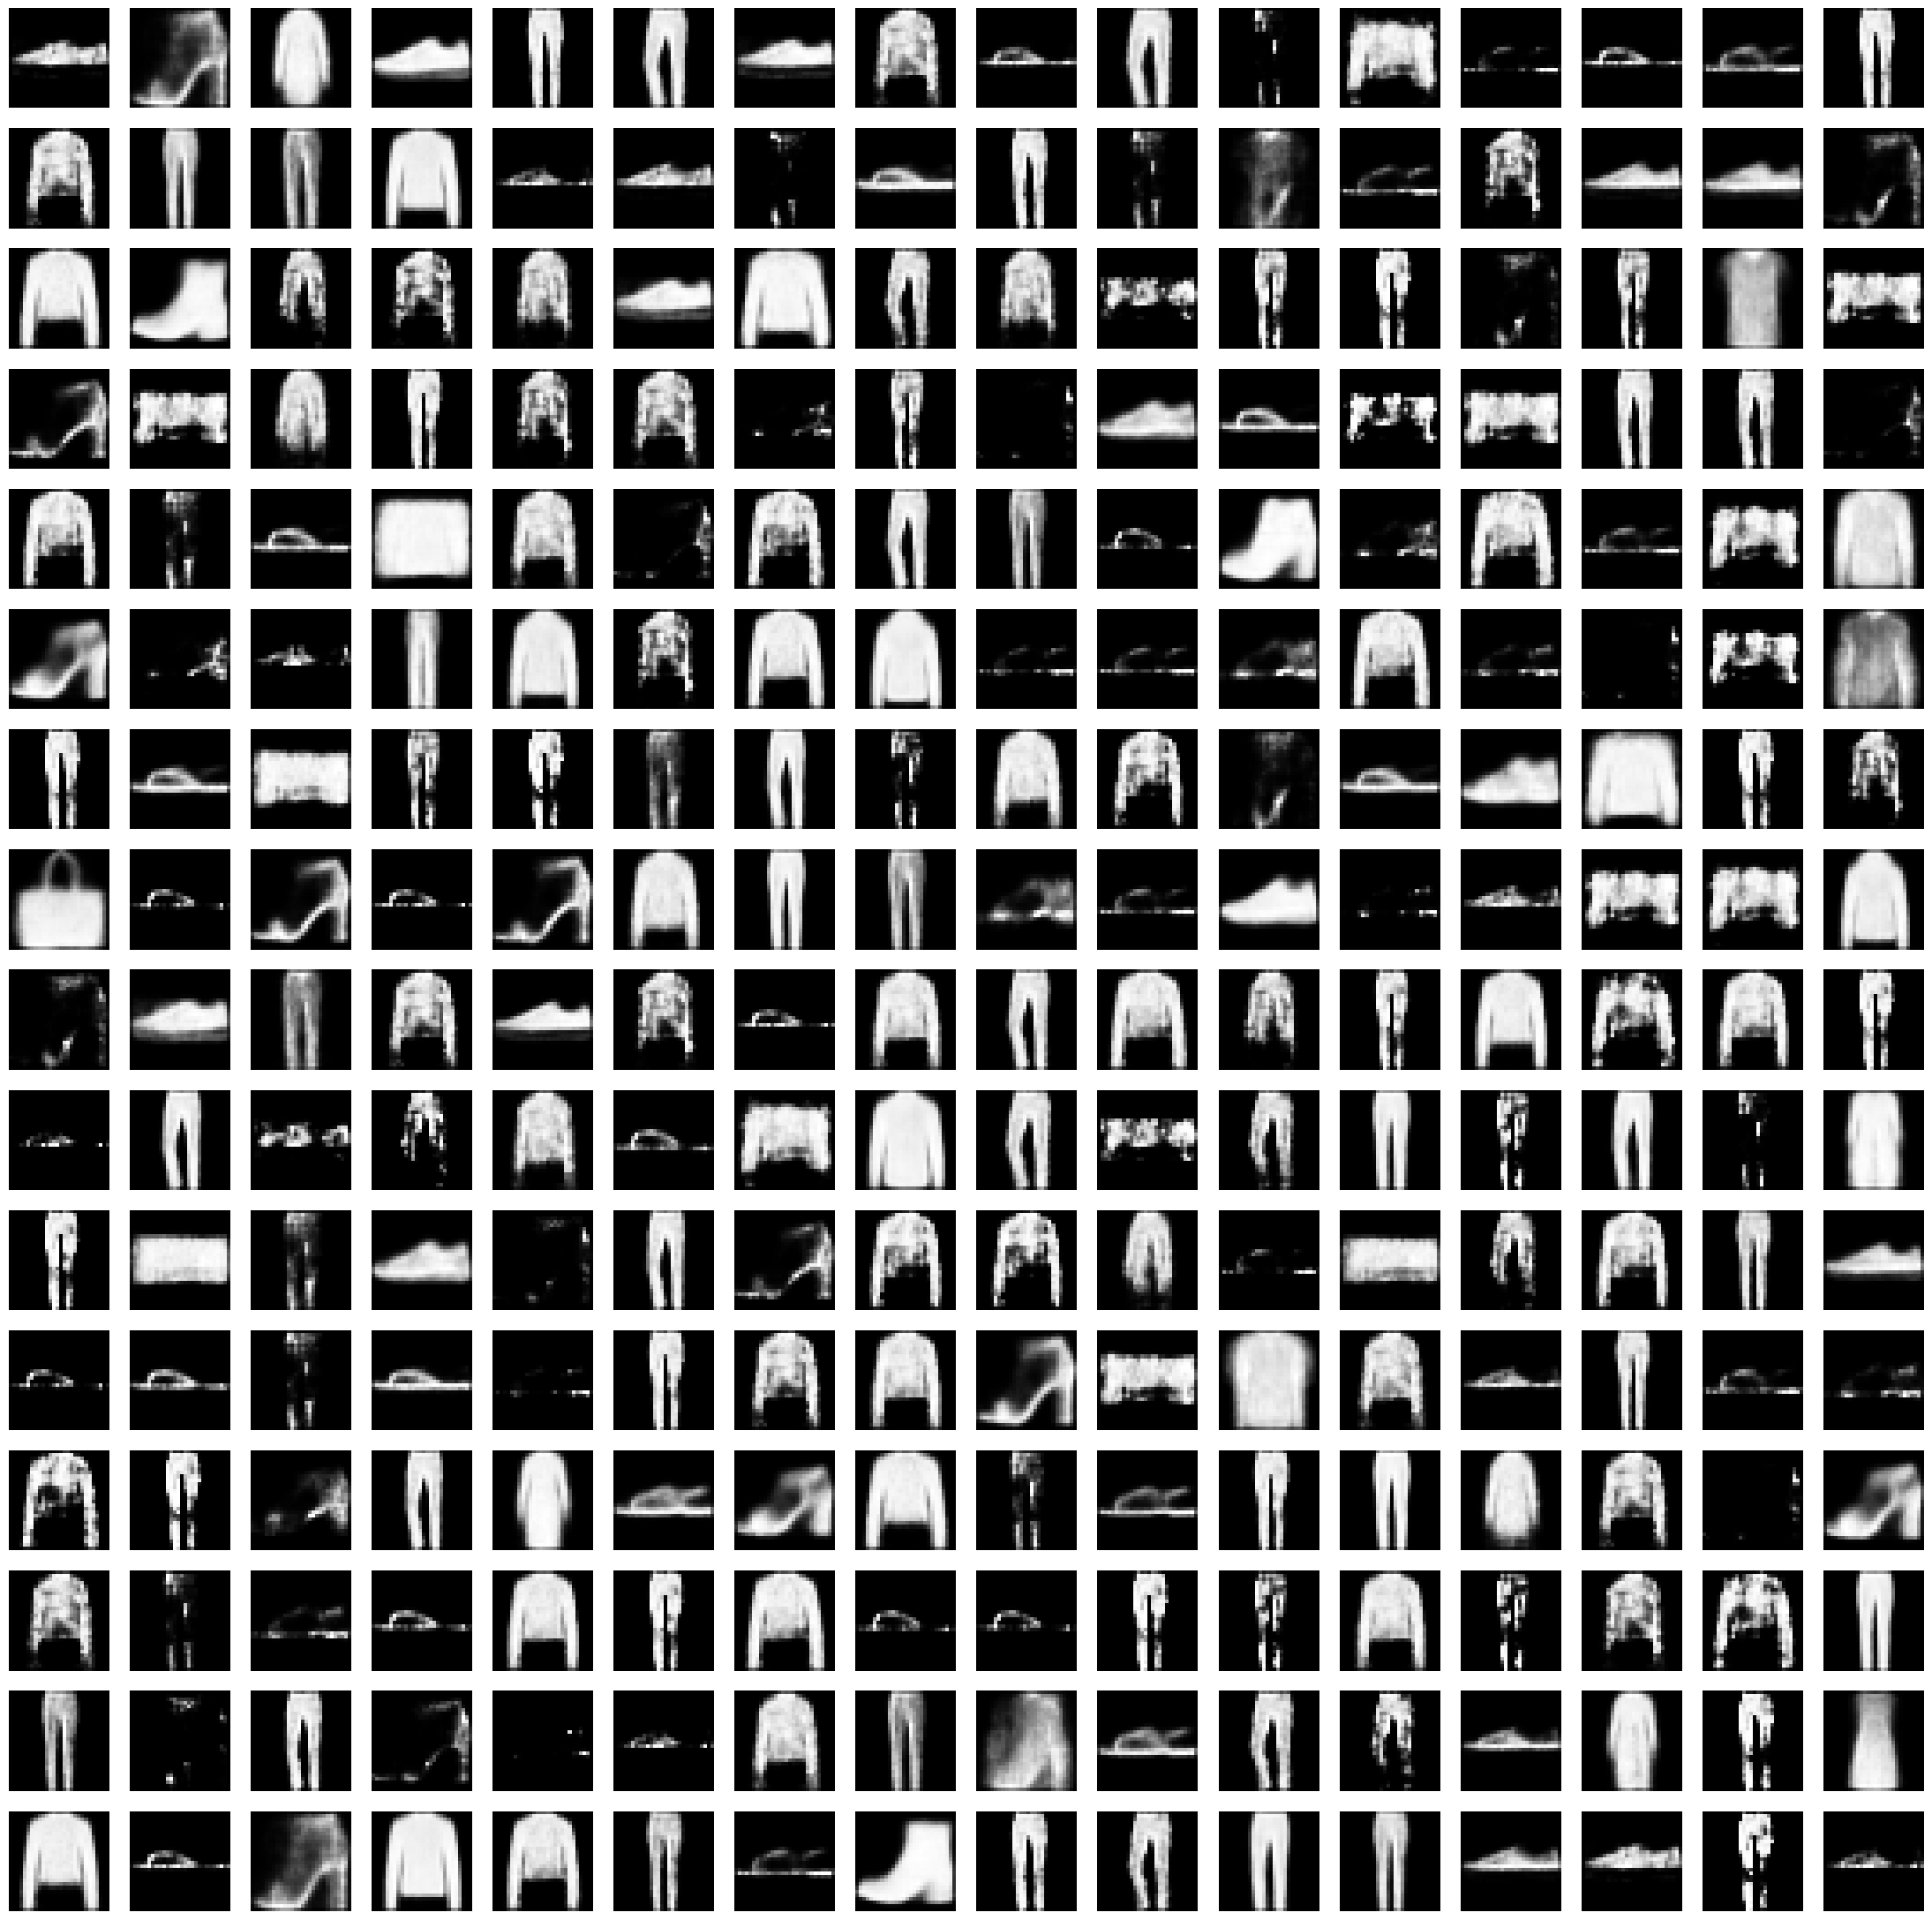

In [17]:
z = np.random.normal(loc=0, scale=4, size=(256,2))  # prior é N(0,1); scale=4 espalha demais os pontos
synth = vae.decoder.predict(z)  # decodifica os 256 pontos

plt.figure(figsize=(28,28))

for i in range(256):
    plt.subplot(16,16,i+1)  # grade 16x16
    plt.imshow(synth[i].reshape((28,28)), cmap="Greys_r")
    plt.axis('off')

plt.show();

In [18]:
idx = 1280  # índice da imagem de exemplo
batch = np.expand_dims(x_train[idx], axis=0)  # adiciona dimensão de lote
batchOfImages = np.expand_dims(batch, axis=-1).astype("float32") / 255  # canal + normalização, igual ao treino
print(batchOfImages.shape)
# obtém z para a imagem escolhida
_, _, z = vae.encoder.predict(batchOfImages)  # usa z amostrado

# reconstrói uma imagem parecida
synth = vae.decoder.predict([z])

z

(1, 28, 28, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 947ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_10
Received: inputs=('Tensor(shape=(1, 2))',)
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 438ms/step


array([[0.7250328, 0.9199173]], dtype=float32)

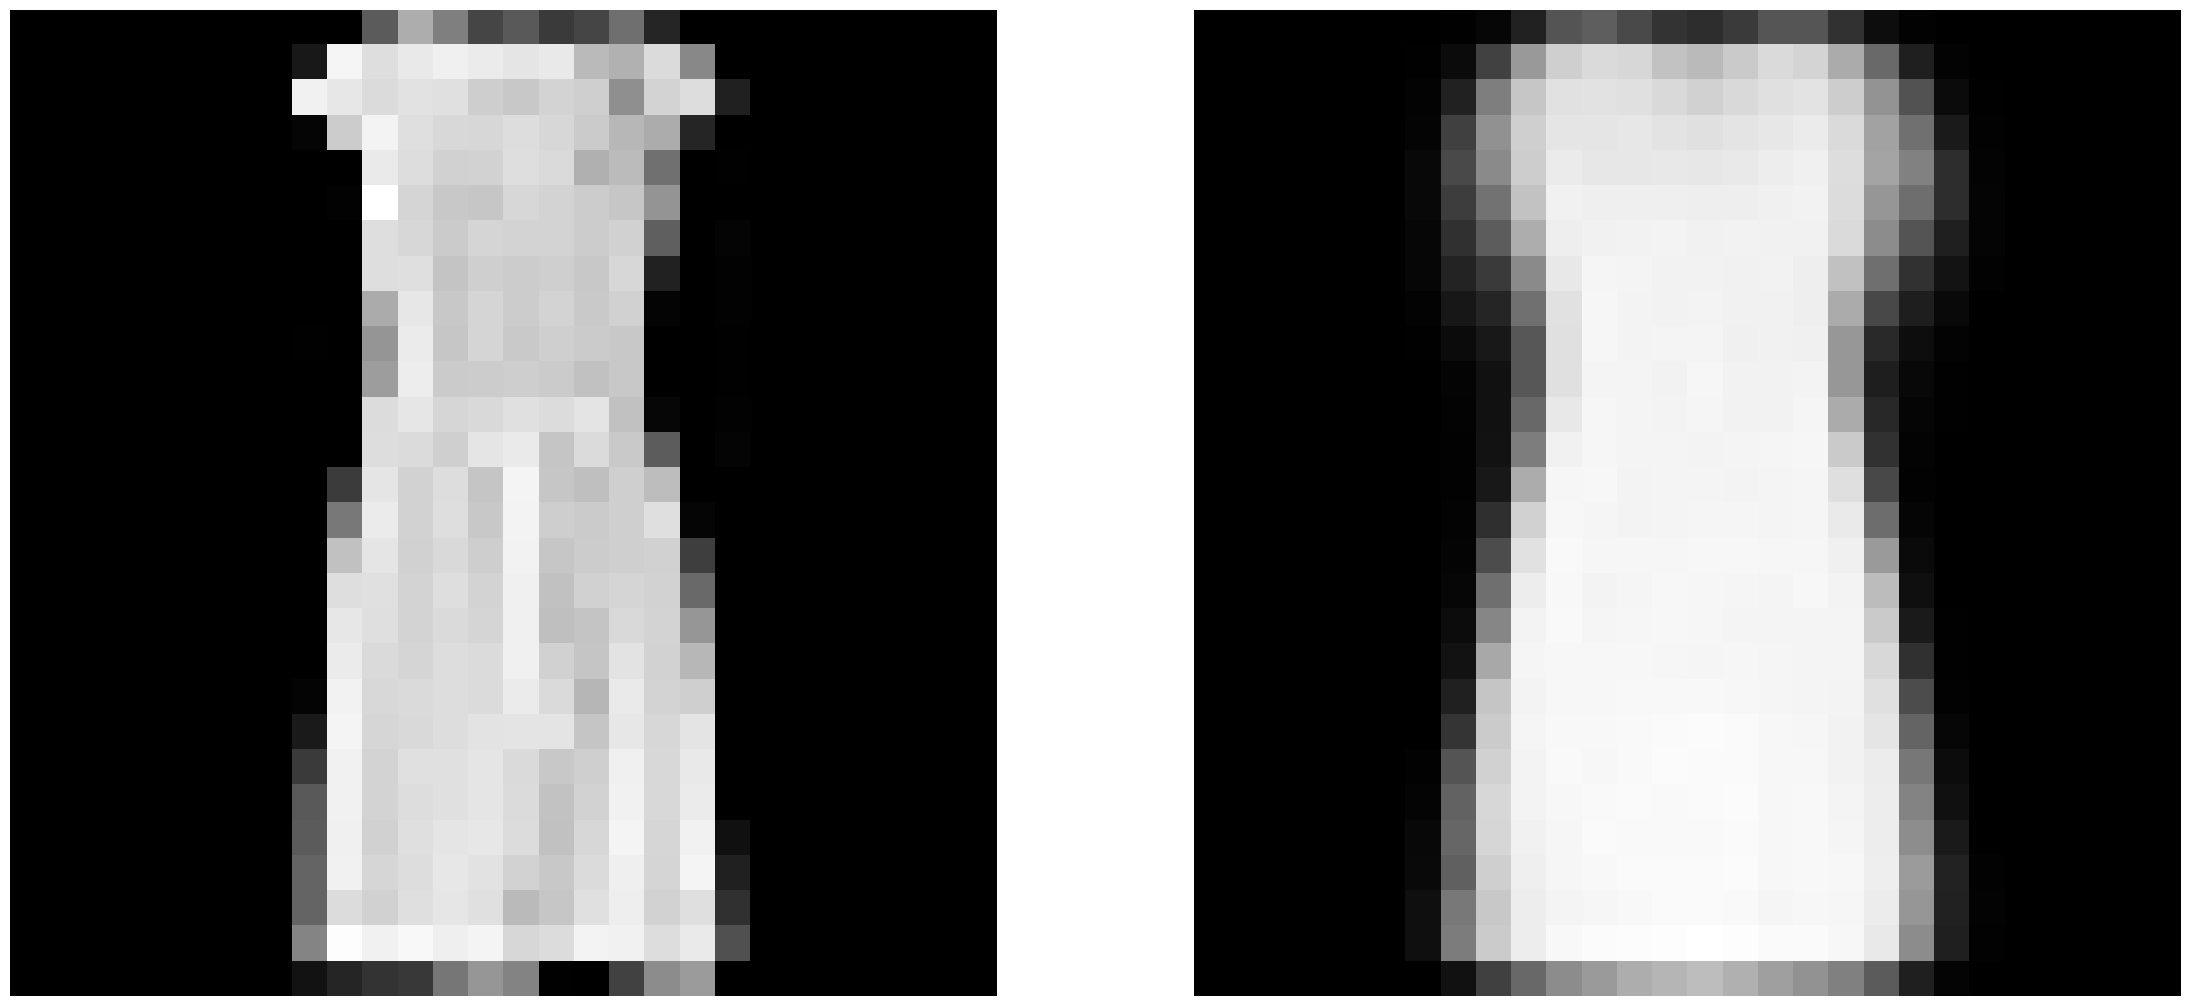

In [19]:
plt.figure(figsize=(28, 28))

# imagem original
plt.subplot(1,2,1)  # original à esquerda
plt.axis('off')
plt.imshow(x_train[idx], cmap="Greys_r")

plt.subplot(1,2,2)  # reconstrução à direita
plt.axis('off')
plt.imshow(synth[0].reshape((28,28)), cmap="Greys_r")
plt.show();

2188/2188 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step


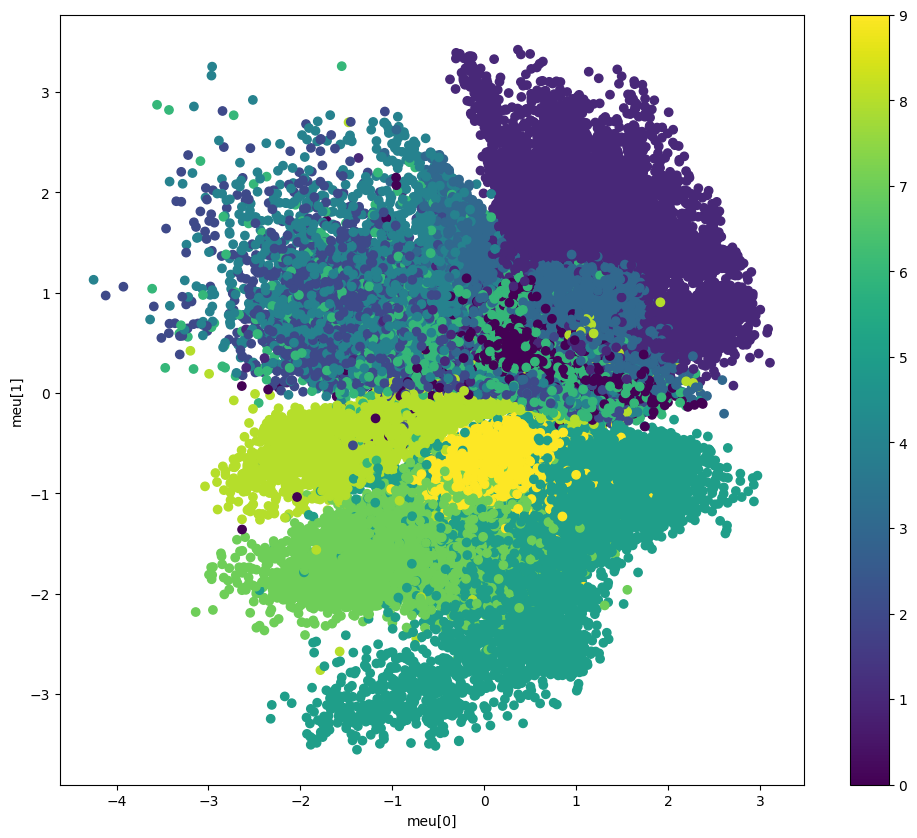

In [20]:
labels = np.concatenate([y_train, y_test], axis=0)
meu, _, _ = vae.encoder.predict(dataset) # médias do latente para todo o dataset
plt.figure(figsize=(12, 10))
plt.scatter(meu[:, 0], meu[:, 1], c=labels) # cada cor é uma classe: mostra os agrupamentos
plt.colorbar()
plt.xlabel("meu[0]")
plt.ylabel("meu[1]")
plt.show();